# 01 – Dataklargøring og baselines

**Spørgsmål:** Hvor mange voksne hunlus pr. fisk er der i et produktionsområde om 1–4 uger?

Notebooken
1. indlæser de cachede lusetællinger fra BarentsWatch (hent dem med `python -m lakselus.hent`),
2. aggregerer til ét ugentligt tal pr. produktionsområde,
3. backtester to baselines – **naiv** (sidste uge) og **sæson-naiv** (samme uge sidste år),
4. giver en skabelon til *din* model, som evalueres på præcis samme måde.

Logikken ligger i `src/lakselus/data.py` og `src/lakselus/evaluering.py`, så Streamlit-siden kan genbruge den.

*Data levert av BarentsWatch. Informasjon om lus er levert av Mattilsynet (NLOD).*

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from lakselus import data, evaluering as ev

pd.set_option("display.precision", 3)

## 1. Rådata

Én række pr. lokalitet × uge. `har_talt == "Nei"` er typisk brakkede lokaliteter (uden fisk) – de tæller ikke med.

In [2]:
raa = data.indlaes_raa()
navne = data.omraade_navne(raa)
print(f"{len(raa):,} rækker, {raa['lokalitet'].nunique():,} lokaliteter, "
      f"{raa['uge_start'].min():%Y-%m-%d} → {raa['uge_start'].max():%Y-%m-%d}")
raa["har_talt"].value_counts()

434,006 rækker, 1,204 lokaliteter, 2018-12-31 → 2026-10-12


har_talt
Ja     231010
Nei    202996
Name: count, dtype: int64

Datakvalitet blandt de lokaliteter, der har talt:

In [3]:
talt = raa[raa["har_talt"] == "Ja"]
pd.Series({
    "andel uden hunlus-værdi": talt["hunlus"].isna().mean(),
    "andel uden havtemperatur": talt["temp"].isna().mean(),
    "rækker uden produktionsområde": int(talt["omraade"].isna().sum()),
    "lokaliteter pr. uge (median)": talt.groupby("uge_start").size().median(),
})

andel uden hunlus-værdi            0.0
andel uden havtemperatur           0.0
rækker uden produktionsområde     57.0
lokaliteter pr. uge (median)     580.0
dtype: float64

## 2. Ugentligt panel pr. produktionsområde

In [4]:
panel = data.ugentligt_panel(raa)
panel["navn"] = panel["omraade"].map(navne)
panel.tail()

,omraade,uge_start,hunlus,temp,n_lok,navn
5286,13,2026-09-14,0.006,10.448,5,Øst-Finnmark
5287,13,2026-09-21,0.022,10.374,5,Øst-Finnmark
5288,13,2026-09-28,0.006,9.982,5,Øst-Finnmark
5289,13,2026-10-05,0.010,9.806,5,Øst-Finnmark
5290,13,2026-10-12,0.018,9.134,5,Øst-Finnmark


In [5]:
dækning = panel.groupby("omraade").agg(
    navn=("navn", "first"),
    lokaliteter_median=("n_lok", "median"),
    uger_uden_tal=("hunlus", lambda s: s.isna().sum()),
    hunlus_gns=("hunlus", "mean"),
)
dækning

,navn,lokaliteter_median,uger_uden_tal,hunlus_gns
omraade,,,,
1,Svenskegrensen til Jæren,6.0,1,0.091
2,Ryfylke,31.0,0,0.193
3,Karmøy til Sotra,86.0,0,0.166
4,Nordhordaland til Stadt,81.0,0,0.172
5,Stadt til Hustadvika,28.0,0,0.181
6,Nordmøre og Sør-Trøndelag,84.0,0,0.170
7,Nord-Trøndelag med Bindal,35.0,0,0.162
8,Helgeland til Bodø,59.0,0,0.143
9,Vestfjorden og Vesterålen,57.0,0,0.138


Område 1 og 13 har få lokaliteter, så deres gennemsnit er mere støjfyldte – det skal huskes, når MAE pr. område læses.

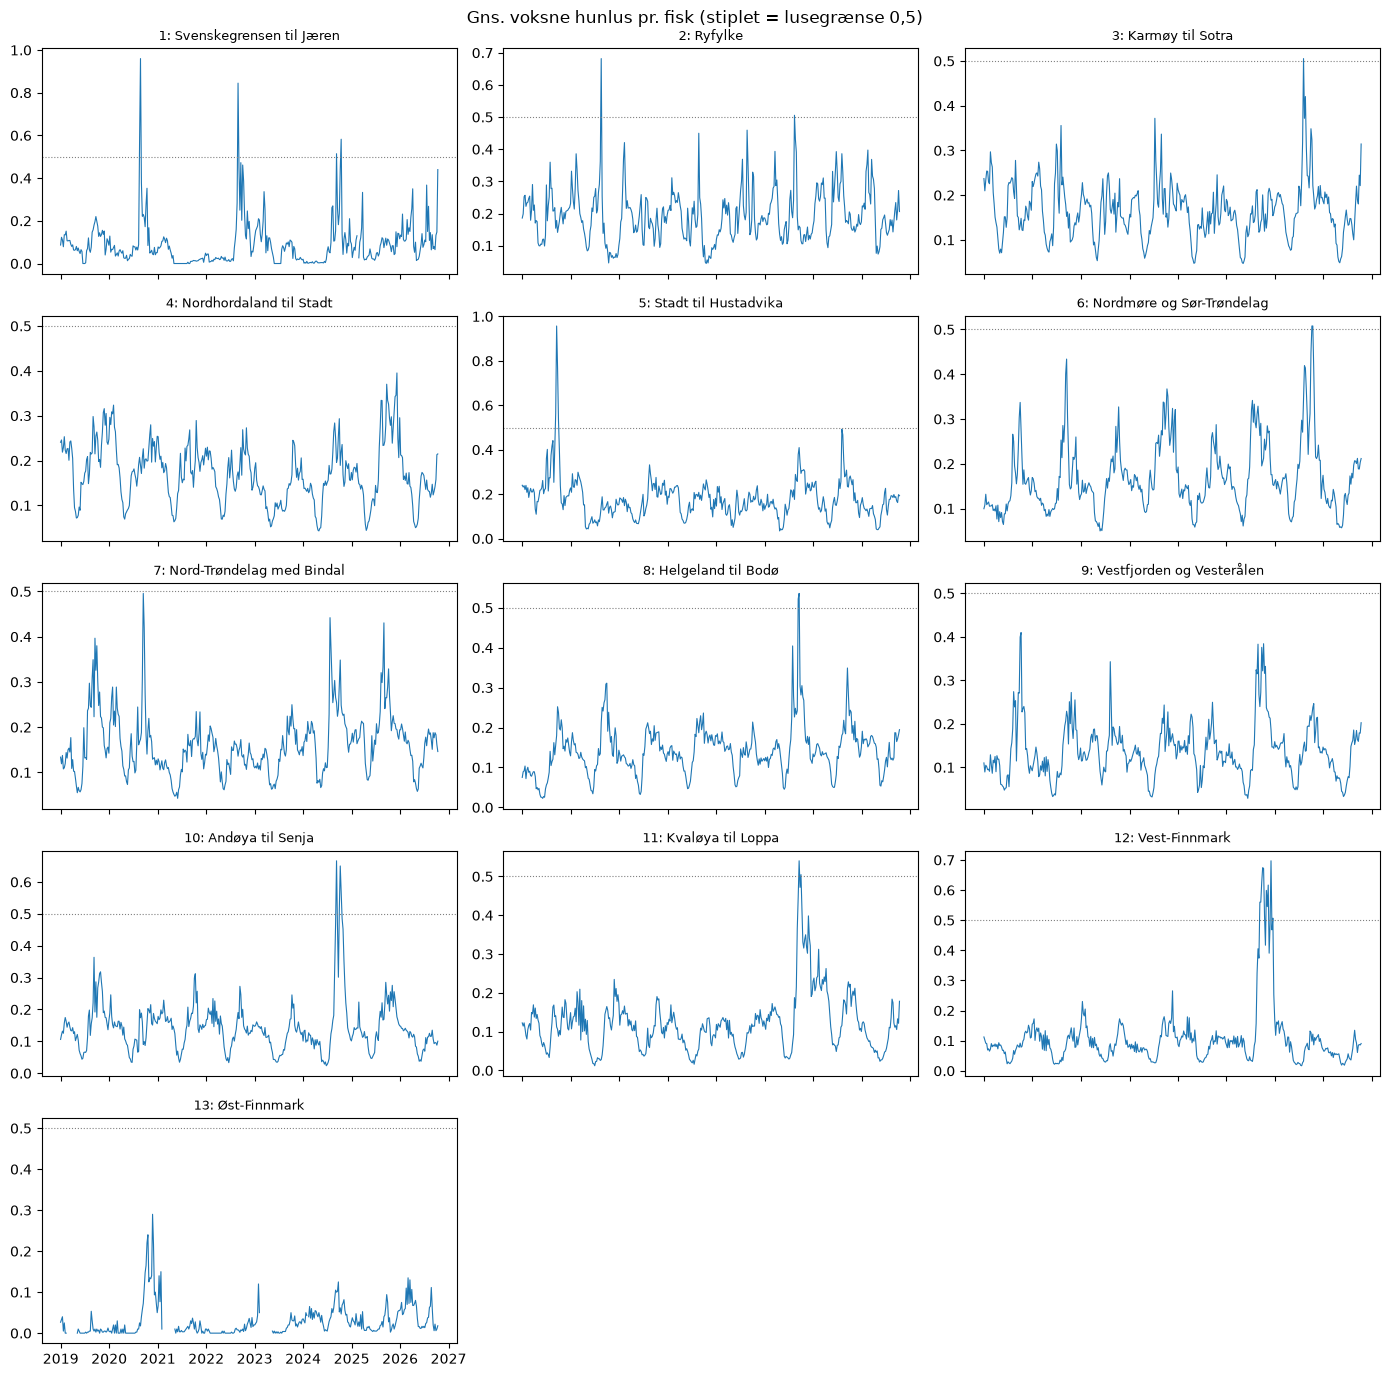

In [6]:
bred = panel.pivot(index="uge_start", columns="omraade", values="hunlus")
fig, akser = plt.subplots(5, 3, figsize=(14, 14), sharex=True)
for ax, omr in zip(akser.flat, bred.columns):
    ax.plot(bred.index, bred[omr], lw=0.8)
    ax.axhline(0.5, color="grey", ls=":", lw=0.8)
    ax.set_title(f"{omr}: {navne[omr]}", fontsize=9)
for ax in akser.flat[len(bred.columns):]:
    ax.set_visible(False)
fig.suptitle("Gns. voksne hunlus pr. fisk (stiplet = lusegrænse 0,5)")
fig.tight_layout()

Sæsonmønster: gennemsnit pr. ISO-uge på tværs af år.

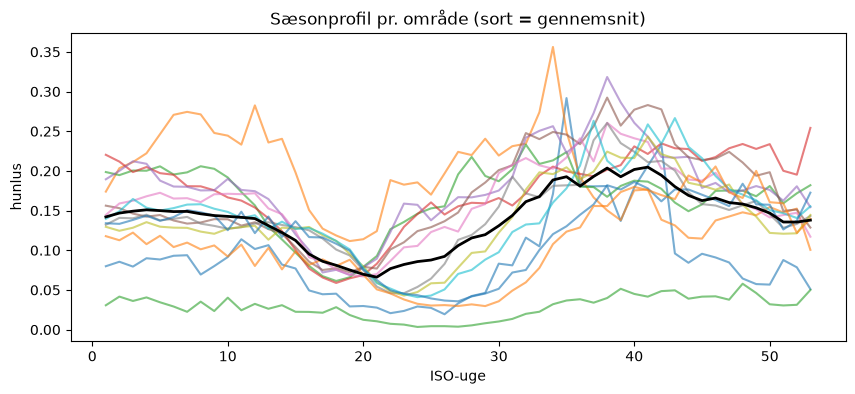

In [7]:
sæson = panel.assign(uge=panel["uge_start"].dt.isocalendar().week).groupby(["uge", "omraade"])["hunlus"].mean().unstack()
ax = sæson.plot(figsize=(10, 4), legend=False, alpha=0.6)
sæson.mean(axis=1).plot(ax=ax, color="black", lw=2)
ax.set(xlabel="ISO-uge", ylabel="hunlus", title="Sæsonprofil pr. område (sort = gennemsnit)");

## 3. Baselines og backtest

Expanding window: for hver uge fra januar 2023 forudsiges 1–4 uger frem **kun med data til og med den uge**.
MAE beregnes kun på de (område, uge, horisont), som alle modeller har forudsagt.

In [8]:
resultater = {
    "naiv": ev.backtest(panel, ev.naiv),
    "saeson_naiv": ev.backtest(panel, ev.saeson_naiv),
}
mae_h = ev.mae(resultater)
mae_h

,naiv,saeson_naiv
h,,
1,0.025,0.061
2,0.034,0.061
3,0.043,0.061
4,0.047,0.061


In [9]:
ev.skill(mae_h)  # 1 − MAE / MAE_naiv; positiv = bedre end naiv

,naiv,saeson_naiv
h,,
1,0.0,-1.463
2,0.0,-0.769
3,0.0,-0.434
4,0.0,-0.299


In [10]:
mae_omr = ev.mae(resultater, efter=["omraade", "h"])
mae_omr.xs(1, level="h").assign(navn=lambda d: d.index.map(navne))

,naiv,saeson_naiv,navn
omraade,,,
1,0.044,0.103,Svenskegrensen til Jæren
2,0.038,0.066,Ryfylke
3,0.024,0.048,Karmøy til Sotra
4,0.020,0.050,Nordhordaland til Stadt
5,0.028,0.057,Stadt til Hustadvika
6,0.022,0.059,Nordmøre og Sør-Trøndelag
7,0.021,0.045,Nord-Trøndelag med Bindal
8,0.021,0.043,Helgeland til Bodø
9,0.019,0.044,Vestfjorden og Vesterålen


**Første aflæsning:** Den naive baseline er klart bedst på alle horisonter – lustallet ændrer sig langsomt fra uge til uge,
mens sidste års niveau er en dårlig rettesnor (behandlinger, biomasse og temperatur varierer fra år til år).
Det er altså **naiv**, modellerne skal slå, og det bliver sværest på 1 uges horisont.

## 4. De færdige modeller

Modellerne ligger i `src/lakselus/modeller.py`, og den fulde evaluering køres med `python -m lakselus.modelrapport`
(et par minutter). Kort fortalt:

- **Mål:** ændringen i lusetal `y(t+h) − y(t)` for h = 1–4 uger – én model pr. horisont (direkte multi-horisont).
  Den naive prognose er dermed udgangspunktet, og modellen skal kun lære at justere den.
- **Kandidater:** naiv + sæsonændring, ridge-regression, gradient boosting (MAE-tab, fælles for alle områder) og et ensemble.
- **Features:** niveau og ændringer over 1–8 uger, rullende snit og spredning, havtemperatur, ISO-uge (sin/cos),
  områdets typiske sæsonændring, antal lokaliteter og kystens samlede niveau.
- **Disciplin:** modellen vælges på **2023–24** (validering) og måles én gang på **2025→** (test).
  At ingen prognose bruger fremtidige data, testes automatisk i `tests/test_modeller.py`.

Cellen nedenfor læser den gemte backtest (samme fil som appen bruger) i stedet for at træne forfra.

In [11]:
from lakselus import modelrapport

res = pd.read_parquet(modelrapport.BACKTEST_FIL)
o = modelrapport.opsummer(res)
v = o["valgt"]
print("Valgt på valideringsperioden:", modelrapport.NAVNE[v])
pd.DataFrame({
    "MAE naiv": o["mae_test"]["naiv"],
    f"MAE {v}": o["mae_test"][v],
    "skill vs naiv": o["skill_test"][v],
    "Diebold–Mariano p": o["dm_test"][v],
    "dækning af 80 %-interval": o["daekning_test"],
}).round(4)

Valgt på valideringsperioden: Gradient boosting


,MAE naiv,MAE gbm,skill vs naiv,Diebold–Mariano p,dækning af 80 %-interval
1,0.023,0.022,0.047,2.880e-02,0.810
2,0.032,0.028,0.122,1.100e-03,0.797
3,0.040,0.032,0.193,0.000e+00,0.784
4,0.045,0.035,0.229,2.000e-04,0.783


Skill pr. model og horisont i testperioden (positiv = bedre end naiv). Kun gradient boosting slår den naive prognose
på alle fire horisonter, og gevinsten vokser med horisonten.

In [12]:
o["skill_test"].rename(columns=modelrapport.NAVNE).round(3)

,Naive (last week),Seasonal naive (same week last year),Naive + seasonal change,Ridge regression,Gradient boosting,Ensemble
h,,,,,,
1,0.0,-1.760,-0.093,-0.060,0.047,-0.006
2,0.0,-0.994,-0.036,0.028,0.122,0.068
3,0.0,-0.593,0.027,0.106,0.193,0.137
4,0.0,-0.417,0.077,0.152,0.229,0.183


## 5. Øvelse: byg din egen model

Prøv selv at slå den naive prognose. Skriv en funktion `min_model(historik, h)`, der returnerer en `pd.Series`
med forudsigelse pr. `omraade`.

- `historik` er panelet **til og med** forecast-ugen – brug kun den, så er der ingen lækage fra fremtiden.
- Idéer: lags af `hunlus` (1, 2, 4 uger), ændring siden sidste uge, ISO-uge (sin/cos), `temp`.
- Skabelonen er en dæmpet trend. Sammenlign med naiv og gradient boosting i testperioden.

In [13]:
def min_model(historik: pd.DataFrame, h: int) -> pd.Series:
    bred = historik.pivot(index="uge_start", columns="omraade", values="hunlus")
    seneste = bred.iloc[-1]
    trend = (bred.iloc[-1] - bred.iloc[-5]) / 4  # gns. ændring pr. uge de sidste 4 uger
    return (seneste + 0.5 * h * trend).clip(lower=0)


resultater["min_model"] = ev.backtest(panel, min_model)
test = {k: ev.periode(r, ev.TEST) for k, r in {**resultater, "gbm": modelrapport.som_dict(res)["gbm"]}.items()}
mae_t = ev.mae(test)
pd.concat({"MAE": mae_t, "skill vs naiv": ev.skill(mae_t)}, axis=1).round(4)

MAE                              skill vs naiv                        \
    naiv saeson_naiv min_model    gbm          naiv saeson_naiv min_model   
h                                                                           
1  0.023       0.064     0.024  0.022           0.0      -1.764    -0.050   
2  0.032       0.064     0.035  0.028           0.0      -1.001    -0.094   
3  0.040       0.064     0.045  0.032           0.0      -0.598    -0.134   
4  0.045       0.064     0.053  0.035           0.0      -0.421    -0.175   

          
     gbm  
h         
1  0.048  
2  0.121  
3  0.193  
4  0.229

## 6. Ærlighedsnoter

- **Uvægtet gennemsnit:** Alle lokaliteter vægter ens; antal fisk pr. lokalitet er ikke i datasættet.
- **Revisioner:** Data hentes som de ser ud i dag. Sene eller rettede indberetninger var ikke nødvendigvis kendt i forecast-ugen, så backtesten kan være en anelse for optimistisk.
- **Få lokaliteter** i område 1 og 13 giver støjfyldte tal.
- **Behandlinger** (afslusning) får tallet til at falde brat og er ikke med som forklarende variabel endnu.